In [1]:
import numpy as np 
import pandas as pd 

import seaborn as sns 
import matplotlib.pyplot as plt

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler, MinMaxScaler
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import OrdinalEncoder, OneHotEncoder

In [17]:
df = pd.read_csv("used_car_dataset.csv")
df.head()

FileNotFoundError: [Errno 2] No such file or directory: 'used_car_dataset.csv'

In [14]:
df.drop(columns = ['listing_id'] ,inplace = True , axis = 1 )

KeyError: "['listing_id'] not found in axis"

In [19]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 9582 entries, 0 to 9581
Data columns (total 11 columns):
 #   Column        Non-Null Count  Dtype 
---  ------        --------------  ----- 
 0   Brand         9582 non-null   object
 1   model         9582 non-null   object
 2   Year          9582 non-null   int64 
 3   Age           9582 non-null   int64 
 4   kmDriven      9535 non-null   object
 5   Transmission  9582 non-null   object
 6   Owner         9582 non-null   object
 7   FuelType      9582 non-null   object
 8   PostedDate    9582 non-null   object
 9   AdditionInfo  9582 non-null   object
 10  AskPrice      9582 non-null   object
dtypes: int64(2), object(9)
memory usage: 823.6+ KB


In [16]:
df.describe()

,Year,Age
count,9582.000000,9582.000000
mean,2016.361094,7.638906
std,4.087226,4.087226
min,1986.000000,0.000000
25%,2014.000000,5.000000
50%,2017.000000,7.000000
75%,2019.000000,10.000000
max,2024.000000,38.000000


In [ ]:
df.isna().sum()

brand                    0
model                    0
year                     0
mileage_km             178
transmission            59
fuel_type               60
engine_cc              121
body_type                0
color                  149
city                    59
seller_type             58
accident_history         0
previous_owners        119
condition_rating       149
photos_count            93
price_egp                0
sold_within_30_days      0
dtype: int64

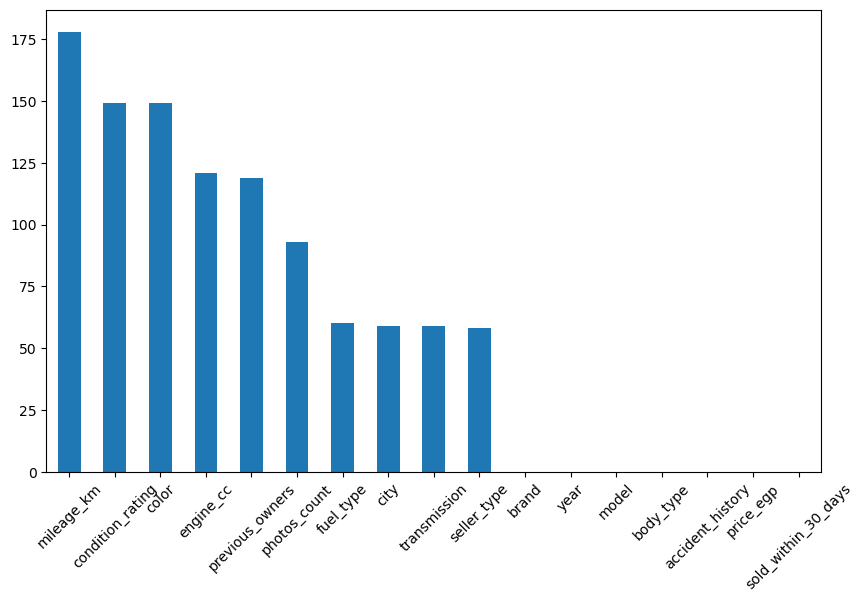

In [ ]:
plt.figure(figsize=(10,6))
df.isna().sum().sort_values(ascending = False).plot(kind = 'bar')
plt.xticks(rotation = 45)
plt.show()

In [3]:
df.select_dtypes('object').isna().sum()

NameError: name 'df' is not defined

In [4]:
df.select_dtypes(['int' , float]).isna().sum()

NameError: name 'df' is not defined

In [5]:
object_nan = [ 'transmission', 'fuel_type', 'color', 'city', 'seller_type', 'condition_rating' , "sold_within_30_days"]

In [6]:
numeric_nan = [ 'mileage_km', 'engine_cc', 'previous_owners', 'photos_count']

In [7]:
plt.figure(figsize = (10 ,6))
sns.heatmap(df.corr(numeric_only= True) ,annot = True ,cmap = 'coolwarm')
plt.xticks(rotation = 45)
plt.show()

NameError: name 'df' is not defined

<Figure size 1000x600 with 0 Axes>

In [8]:
df.duplicated().sum()

NameError: name 'df' is not defined

In [9]:
df.drop_duplicates(inplace = True)
df.reset_index(drop= True , inplace = True)
df.duplicated().sum()

NameError: name 'df' is not defined

In [10]:
en = [col for col in df.select_dtypes("object").columns]
for i in en :
    print(f"{i}: {df[i].nunique()}")
    print(f"{i}: {df[i].unique()}")
    print("*" * 20)

NameError: name 'df' is not defined

In [11]:
df["brand"] = df["brand"].str.strip().str.title()

NameError: name 'df' is not defined

In [ ]:
df["city"] = df["city"].replace({
                                                "giza" : "Giza" ,
                                               'GIZA' : 'Giza',
                                                "alexandria" : "Alexandria" ,
                                               'ALEXANDRIA' : 'Alexandria',
                                                "cairo" : "Cairo" ,
                                               'CAIRO' : 'Cairo',
                                                "ASSIUT" : "Assiut" ,
                                               'assiut' : 'Assiut',
                                                "TANTA" : "Tanta" ,
                                               'TANTA' : 'Tanta',
                                                "MANSOURA" : "Mansoura" ,
                                               'mansoura' : 'Mansoura',
                                                "port said" : "Port Said" ,
                                               'PORT SAID' : 'Port Said',
                                                "SUEZ" : "Suez" ,
                                               'suez' : 'Suez',
                                                "banha" : "Banha" ,
                                               'BANHA' : 'Banha'
})

In [ ]:
df["accident_history"] = df["accident_history"].replace({"N" : "No" ,
                                                                   'Y' : 'Yes'})
df["seller_type"] = df["seller_type"].replace({"individual" : "Individual" ,
                                                                   'dealer' : 'Dealer'})

In [ ]:
en = [col for col in df.select_dtypes("object").columns]
for i in en :
    print(f"{i}: {df[i].nunique()}")
    print(f"{i}: {df[i].unique()}")
    print("*" * 20)

brand: 14
brand: ['Mg' 'Kia' 'Skoda' 'Fiat' 'Mitsubishi' 'Toyota' 'Hyundai' 'Nissan'
 'Chevrolet' 'Mercedes' 'Bmw' 'Renault' 'Mercedes-Benz' 'Chery']
********************
model: 14
model: ['ZS' 'Cerato' 'Octavia' 'Tipo' 'Lancer' 'Corolla' 'Elantra' 'Sunny'
 'Tucson' 'Optra' 'C200' '320i' 'Logan' 'Tiggo 7']
********************
transmission: 4
transmission: ['Automatic' 'Manual' 'Auto' nan 'MT']
********************
fuel_type: 3
fuel_type: ['Diesel' 'Petrol' 'Hybrid' nan]
********************
body_type: 2
body_type: ['SUV' 'Sedan']
********************
color: 7
color: ['Black' 'Grey' 'Silver' 'White' 'Blue' nan 'Beige' 'Red']
********************
city: 10
city: ['Giza' 'Banha' 'Alexandria' 'Cairo' 'Mansoura' nan 'Assiut' 'Suez'
 'Port Said' 'Tanta' 'tanta']
********************
seller_type: 2
seller_type: ['Individual' 'Dealer' nan]
********************
accident_history: 2
accident_history: ['No' 'Yes']
********************
condition_rating: 4
condition_rating: ['Fair' 'Good' 'Excellent

**Prediction Regression**

In [ ]:
X = df.drop("price_egp",axis = 1)
y = df["price_egp"]

In [ ]:
X_train, X_test, y_train, y_test = train_test_split(X,y , test_size = .2 , random_state =1234 )

In [ ]:
X_train.shape ,X_test.shape ,  y_train.shape , y_test.shape 

((2368, 16), (592, 16), (2368,), (592,))

In [ ]:
print(f"Numeric_Nan: {numeric_nan}")
print(f"Object_Nan: {object_nan}")

Numeric_Nan: ['mileage_km', 'engine_cc', 'previous_owners', 'photos_count']
Object_Nan: ['transmission', 'fuel_type', 'color', 'city', 'seller_type', 'condition_rating', 'sold_within_30_days']


In [ ]:
for col in numeric_nan:
    print(f"Skew {col}: {X_train[col].skew():.3f} ")

Skew mileage_km: 28.602 
Skew engine_cc: 23.196 
Skew previous_owners: 1.238 
Skew photos_count: 22.617 


In [ ]:
impute = SimpleImputer(strategy='median')
X_train[numeric_nan] = impute.fit_transform(X_train[numeric_nan])
X_test[numeric_nan] = impute.transform(X_test[numeric_nan])
X_train[numeric_nan].isna().sum()

mileage_km         0
engine_cc          0
previous_owners    0
photos_count       0
dtype: int64

In [ ]:
X_train[object_nan].isna().sum()

transmission            49
fuel_type               48
color                  121
city                    47
seller_type             46
condition_rating       119
sold_within_30_days      0
dtype: int64

In [ ]:
impute_obj = SimpleImputer(strategy='most_frequent')
X_train[object_nan] = impute_obj.fit_transform(X_train[object_nan])
X_test[object_nan] = impute_obj.transform(X_test[object_nan])
X_train[object_nan].isna().sum()

transmission           0
fuel_type              0
color                  0
city                   0
seller_type            0
condition_rating       0
sold_within_30_days    0
dtype: int64

In [ ]:
X_train.isna().sum()

brand                  0
model                  0
year                   0
mileage_km             0
transmission           0
fuel_type              0
engine_cc              0
body_type              0
color                  0
city                   0
seller_type            0
accident_history       0
previous_owners        0
condition_rating       0
photos_count           0
sold_within_30_days    0
dtype: int64

In [ ]:
encoding = X_train.select_dtypes(include='object').columns

encoder = OneHotEncoder()

X_train_encoded = encoder.fit_transform(X_train[encoding])
X_test_encoded = encoder.transform(X_test[encoding])

In [ ]:
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

ValueError: could not convert string to float: 'Kia'

In [ ]:
from sklearn.neighbors import KNeighborsRegressor
from sklearn.naive_bayes import GaussianNB
from sklearn.svm import SVR

from sklearn.metrics import mean_absolute_error, mean_squared_error, root_mean_squared_error, r2_score

In [ ]:
model = KNeighborsRegressor(n_neighbors= 5, metric = 'minkowski', p = 2 )
model.fit(X_train , y_train)

ValueError: could not convert string to float: 'Kia'

In [ ]:
y_pred = model.predict(X_test)

In [ ]:
R_Train = r2_score(y_train,model.predict(X_train))
R_Test  =  r2_score(y_test,model.predict(X_test))

In [ ]:
R_Train , R_Test

## Model Comparison


In [ ]:
_Xtr = globals().get("X_train_scaled", X_train)
_Xte = globals().get("X_test_scaled", X_test)

from sklearn.ensemble import GradientBoostingRegressor
from sklearn.ensemble import RandomForestRegressor
from sklearn.linear_model import LinearRegression
from sklearn.neighbors import KNeighborsRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

models = {
    "Linear Regression": LinearRegression(),
    "KNN": KNeighborsRegressor(),
    "Random Forest": RandomForestRegressor(n_estimators=200, random_state=42, n_jobs=-1),
    "Gradient Boosting": GradientBoostingRegressor(random_state=42),
}

results = []
for name, m in models.items():
    m.fit(_Xtr, y_train)
    p = m.predict(_Xte)
    results.append({"Model": name,
                    "Train R2": r2_score(y_train, m.predict(_Xtr)),
                    "Test R2": r2_score(y_test, p),
                    "MAE": mean_absolute_error(y_test, p),
                    "RMSE": np.sqrt(mean_squared_error(y_test, p))})

results_df = pd.DataFrame(results).sort_values("Test R2", ascending=False).reset_index(drop=True)
results_df